In [24]:
from google.colab import drive
drive.mount('/content/drive')

%pip -q install pandas matplotlib pillow torchvision scipy opencv-python-headless

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
from pathlib import Path
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision.models import resnet18

PROJECT_DIR = Path(
    '/content/drive/MyDrive/rehabilitation-project-data'
)

VIDEO_DIR = PROJECT_DIR / 'own_videos' / 'sils'

RESULTS = PROJECT_DIR / 'results' / 'own_videos' / 'sils_cross_view'

ROOT = Path('/content/drive/MyDrive/rehabilitation-project-data/models/sils')

CHECKPOINT = ROOT / 'epoch_3.pth'
NORM_FILE = ROOT / 'final_train_norm_params.json'

EXERCISES = [f'exercise_{i:02d}' for i in range(1, 7)]
CAMERAS = ['cam1', 'cam2']

BATCH_SIZE = 64

CAM2_OFFSETS = {exercise: 0 for exercise in EXERCISES}

RESULTS.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT.is_file(), f'Cannot find checkpoint: {CHECKPOINT}'
assert NORM_FILE.is_file(), f'Cannot find normalization parameters: {NORM_FILE}'

with open(NORM_FILE) as f:
    norm = json.load(f)

ANGLE_MEAN = float(norm['mean'])
ANGLE_STD = float(norm['std'])

assert ANGLE_STD > 0

print('Angle mean:', ANGLE_MEAN)
print('Angle std:', ANGLE_STD)
print('Results:', RESULTS)

Angle mean: 141.99251345365988
Angle std: 29.703175153148667
Results: /content/drive/MyDrive/rehabilitation-project-data/results/own_videos/sils_cross_view


In [26]:
from types import SimpleNamespace

class BaselineSilsModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()

        net = resnet18(weights=None)

        net.conv1 = nn.Conv2d(
            1, 64,
            kernel_size=7,
            stride=2,
            padding=3,
            bias=False
        )

        feat_dim = net.fc.in_features
        net.fc = nn.Identity()

        self.backbone = net

        self.head = nn.Sequential(
            nn.Linear(feat_dim, cfg.hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(cfg.hidden_dim, 1)
        )

    def forward(self, x):
        f = self.backbone(x)
        y = self.head(f).squeeze(-1)
        return y


cfg = SimpleNamespace(hidden_dim=256)

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

checkpoint = torch.load(
    CHECKPOINT,
    map_location='cpu',
    weights_only=False
)

model = BaselineSilsModel(cfg)

model.load_state_dict(
    checkpoint['model_state_dict'],
    strict=True
)

model = model.to(DEVICE)
model.eval()

print('Checkpoint epoch:', checkpoint.get('epoch'))
print('Device:', DEVICE)

with torch.inference_mode():
    test_output = model(
        torch.zeros(1, 1, 224, 224, device=DEVICE)
    )

print('Output shape:', tuple(test_output.shape))

Checkpoint epoch: 3
Device: cpu
Output shape: (1,)


In [27]:
def video_path(exercise, camera):
    path = VIDEO_DIR / exercise / f'{camera}.mp4'

    if not path.is_file():
        raise FileNotFoundError(f'Video not found: {path}')

    return path


inventory = []

for exercise in EXERCISES:
    for camera in CAMERAS:
        path = video_path(exercise, camera)

        cap = cv2.VideoCapture(str(path))

        if not cap.isOpened():
            raise RuntimeError(f'Cannot open video: {path}')

        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        cap.release()

        if fps <= 0 or count <= 0:
            raise ValueError(f'Invalid video: {path}')

        inventory.append({
            'exercise': exercise,
            'camera': camera,
            'frames': count,
            'fps': fps,
            'duration_s': count / fps
        })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

for exercise in EXERCISES:
    pair = inventory_df[
        inventory_df['exercise'] == exercise
    ]

    fps1 = pair.iloc[0]['fps']
    fps2 = pair.iloc[1]['fps']

    if abs(fps1 - fps2) > 0.01:
        raise ValueError(
            f'{exercise}: cameras have different FPS'
        )

,exercise,camera,frames,fps,duration_s
0,exercise_01,cam1,517,30.0,17.233333
1,exercise_01,cam2,500,30.0,16.666667
2,exercise_02,cam1,556,30.0,18.533333
3,exercise_02,cam2,567,30.0,18.900000
4,exercise_03,cam1,375,30.0,12.500000
5,exercise_03,cam2,369,30.0,12.300000
6,exercise_04,cam1,375,30.0,12.500000
7,exercise_04,cam2,338,30.0,11.266667
8,exercise_05,cam1,290,30.0,9.666667
9,exercise_05,cam2,311,30.0,10.366667


In [28]:
def preprocess_frame(frame_bgr):
    gray = cv2.cvtColor(
        frame_bgr,
        cv2.COLOR_BGR2GRAY
    )

    resized = cv2.resize(
        gray,
        (224, 224),
        interpolation=cv2.INTER_NEAREST
    )

    arr = resized.astype(np.float32) / 255.0

    return torch.from_numpy(arr).unsqueeze(0)

In [29]:
def predict_video(exercise, camera):
    path = video_path(exercise, camera)

    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise RuntimeError(f'Cannot open video: {path}')

    fps = float(cap.get(cv2.CAP_PROP_FPS))

    if fps <= 0:
        cap.release()
        raise ValueError(f'Invalid FPS: {path}')

    predictions = []
    batch = []
    frame_index = 0

    def process_batch():
        if not batch:
            return

        x = torch.stack(batch).to(DEVICE)

        with torch.inference_mode():
            output = model(x)

        # Model predicts normalized angles
        output = output.reshape(-1).cpu().numpy()

        # Convert normalized angles back to degrees
        output = output * ANGLE_STD + ANGLE_MEAN

        for value in output:
            predictions.append(float(value))

        batch.clear()

    while True:
        ok, frame = cap.read()

        if not ok:
            break

        batch.append(preprocess_frame(frame))

        if len(batch) == BATCH_SIZE:
            process_batch()

        frame_index += 1

    process_batch()

    cap.release()

    return pd.DataFrame({
        'exercise': exercise,
        'camera': camera,
        'frame_index': np.arange(len(predictions)),
        'time_s': np.arange(len(predictions)) / fps,
        'fps': fps,
        'predicted_angle_deg': predictions
    })

In [32]:
all_predictions = pd.concat(
    [
        predict_video(exercise, camera)
        for exercise in EXERCISES
        for camera in CAMERAS
    ],
    ignore_index=True
)

assert np.isfinite(
    all_predictions['predicted_angle_deg']
).all()

all_predictions.to_csv(
    RESULTS / 'all_predictions.csv',
    index=False
)

display(all_predictions.head())

print('Total predicted frames:', len(all_predictions))

,exercise,camera,frame_index,time_s,fps,predicted_angle_deg
0,exercise_01,cam1,0,0.000000,30.0,161.577606
1,exercise_01,cam1,1,0.033333,30.0,158.873276
2,exercise_01,cam1,2,0.066667,30.0,159.054901
3,exercise_01,cam1,3,0.100000,30.0,158.036835
4,exercise_01,cam1,4,0.133333,30.0,159.398575


Total predicted frames: 4756


In [33]:
def aligned_pair(exercise):
    a = all_predictions[
        (all_predictions['exercise'] == exercise) &
        (all_predictions['camera'] == CAMERAS[0])
    ].copy()

    b = all_predictions[
        (all_predictions['exercise'] == exercise) &
        (all_predictions['camera'] == CAMERAS[1])
    ].copy()

    av = a['predicted_angle_deg'].to_numpy()
    bv = b['predicted_angle_deg'].to_numpy()

    offset = int(CAM2_OFFSETS[exercise])

    if offset >= 0:
        bv = bv[offset:]
    else:
        av = av[-offset:]

    n = min(len(av), len(bv))

    if n < 2:
        raise ValueError(
            f'{exercise}: not enough aligned frames'
        )

    return av[:n], bv[:n]


summary = []

for exercise in EXERCISES:
    a, b = aligned_pair(exercise)

    rom_a = float(np.ptp(a))
    rom_b = float(np.ptp(b))

    if np.std(a) > 0 and np.std(b) > 0:
        corr = float(np.corrcoef(a, b)[0, 1])
    else:
        corr = np.nan

    summary.append({
        'exercise': exercise,
        'aligned_frames': len(a),
        'camera_1_rom_deg': rom_a,
        'camera_2_rom_deg': rom_b,
        'rom_difference_deg': abs(rom_a - rom_b),
        'cross_view_mae_deg': float(
            np.mean(np.abs(a - b))
        ),
        'cross_view_rmse_deg': float(
            np.sqrt(np.mean((a - b) ** 2))
        ),
        'pearson_correlation': corr
    })

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    RESULTS / 'cross_view_summary.csv',
    index=False
)

display(summary_df.round(3))

,exercise,aligned_frames,camera_1_rom_deg,camera_2_rom_deg,rom_difference_deg,cross_view_mae_deg,cross_view_rmse_deg,pearson_correlation
0,exercise_01,500,20.789,34.106,13.317,6.092,7.777,0.437
1,exercise_02,556,35.768,28.699,7.069,4.622,6.094,0.756
2,exercise_03,369,11.245,35.846,24.601,5.253,8.142,-0.064
3,exercise_04,338,62.523,33.701,28.822,21.317,24.550,0.186
4,exercise_05,290,10.301,6.938,3.364,4.752,5.460,-0.297
5,exercise_06,261,12.853,11.532,1.321,5.733,6.785,-0.397


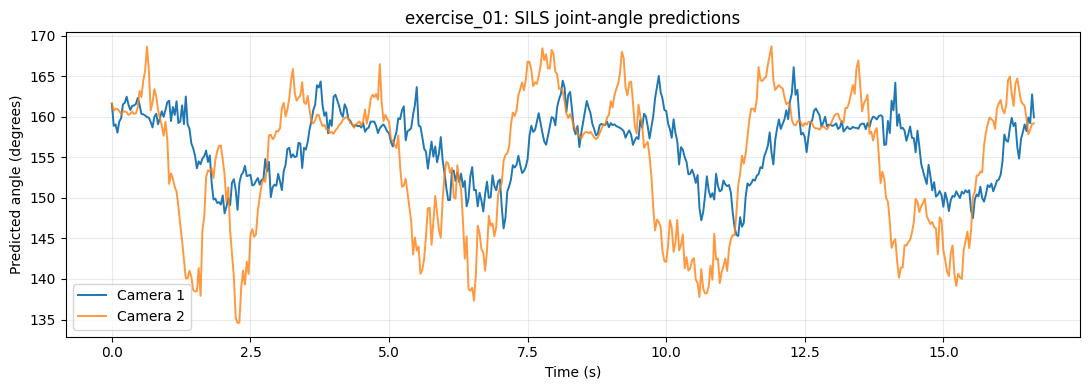

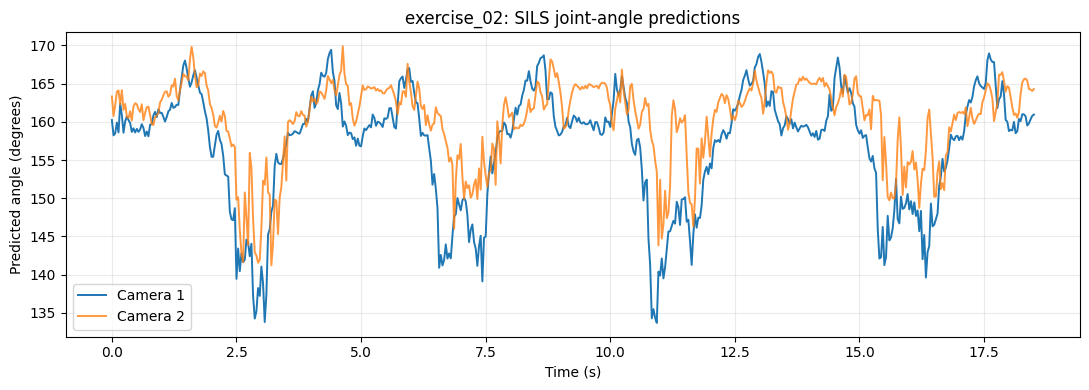

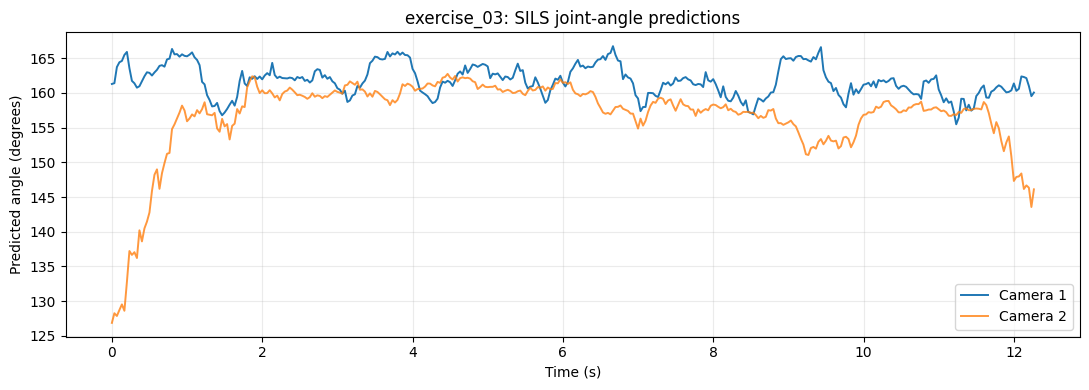

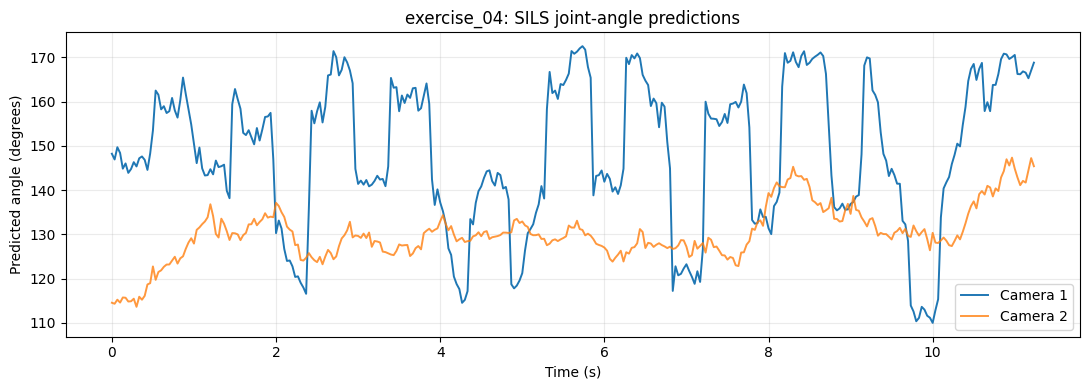

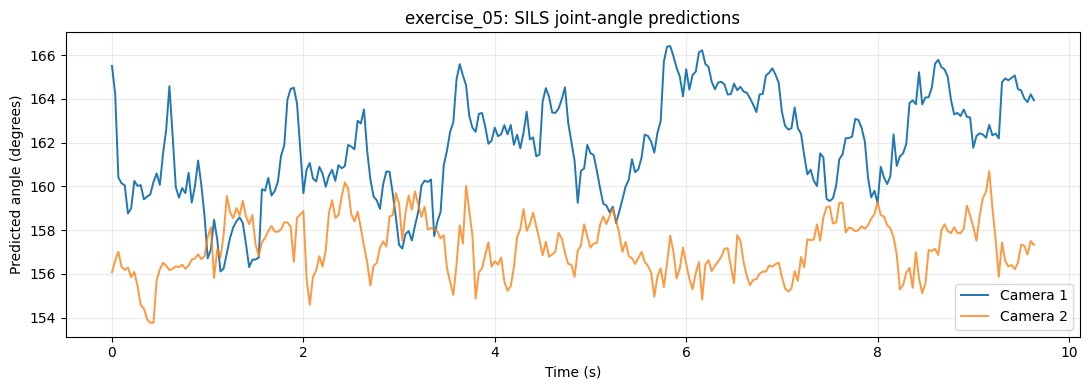

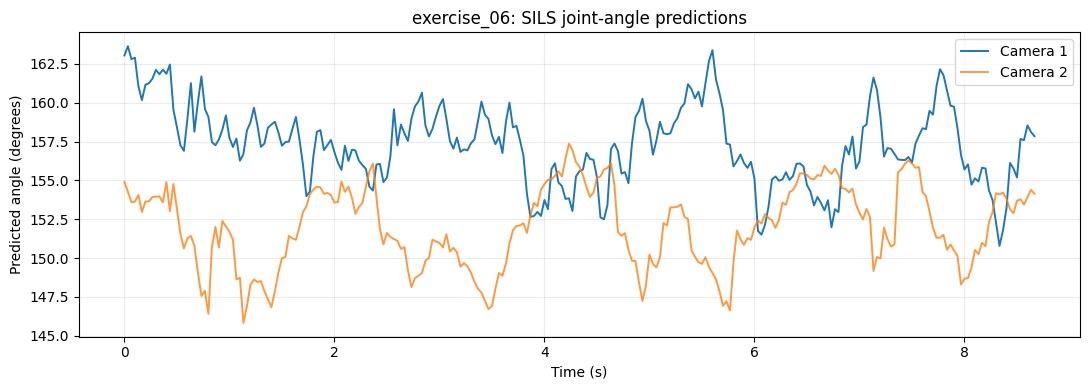

Results saved: /content/drive/MyDrive/rehabilitation-project-data/results/own_videos/sils_cross_view


In [34]:
for exercise in EXERCISES:
    a, b = aligned_pair(exercise)

    pair = inventory_df[
        inventory_df['exercise'] == exercise
    ]

    fps = float(pair.iloc[0]['fps'])

    t = np.arange(len(a)) / fps

    plt.figure(figsize=(11, 4))

    plt.plot(
        t, a,
        label='Camera 1',
        linewidth=1.4
    )

    plt.plot(
        t, b,
        label='Camera 2',
        linewidth=1.4,
        alpha=0.8
    )

    plt.title(
        f'{exercise}: SILS joint-angle predictions'
    )

    plt.xlabel('Time (s)')
    plt.ylabel('Predicted angle (degrees)')

    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        RESULTS / f'{exercise}_angles.png',
        dpi=160
    )

    plt.show()

print('Results saved:', RESULTS)